# Portfolio Optimisation with CVXPY

Quadratic programming for the global minimum-variance portfolio, the maximum-Sharpe (tangency) portfolio and the efficient frontier, under realistic constraints.

---
## 1. Data and optimisation

GMV weights:       [0.287 0.277 0.    0.248 0.188]
Tangency weights:  [0.35  0.306 0.109 0.158 0.078]
GMV:      return 0.0974 | risk 0.0610
Tangency: return 0.1074 | risk 0.0642 | Sharpe 1.360 (rf = 2%)


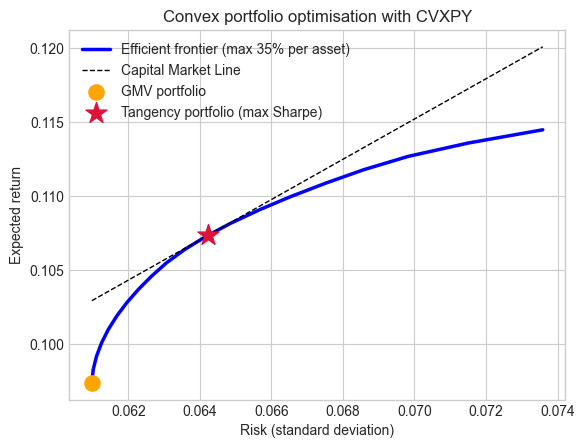

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

np.random.seed(42)
n_assets = 5
mu = np.array([0.14, 0.11, 0.09, 0.07, 0.05])
A_rand = np.random.randn(n_assets, n_assets)
Sigma = A_rand @ A_rand.T * 0.004 + np.diag([0.01, 0.008, 0.006, 0.005, 0.003])

w_cap = 0.35   # concentration limit per asset

# Global minimum-variance (GMV) portfolio, with the same constraints as the frontier
w = cp.Variable(n_assets)
prob_gmv = cp.Problem(cp.Minimize(cp.quad_form(w, Sigma)), [cp.sum(w) == 1, w >= 0, w <= w_cap])
prob_gmv.solve()
risk_gmv = np.sqrt(prob_gmv.value)
ret_gmv = mu @ w.value

# Efficient frontier with a concentration limit (at most 35% per asset)
# With w_i <= 35% the highest attainable return is below max(mu)
w_max = cp.Variable(n_assets)
ret_max = cp.Problem(cp.Maximize(mu @ w_max), [cp.sum(w_max) == 1, w_max >= 0, w_max <= w_cap]).solve()
target_returns = np.linspace(ret_gmv, ret_max, 20)
risks = []
for r_t in target_returns:
    w_tmp = cp.Variable(n_assets)
    p = cp.Problem(cp.Minimize(cp.quad_form(w_tmp, Sigma)), [cp.sum(w_tmp) == 1, w_tmp >= 0, w_tmp <= w_cap, mu @ w_tmp >= r_t])
    p.solve()
    risks.append(np.sqrt(p.value) if p.status == cp.OPTIMAL else np.nan)

# Tangency (maximum-Sharpe) portfolio via the Charnes-Cooper transformation:
# y = kappa * w with kappa = sum(y) > 0; normalising (mu - rf)^T y = 1 makes the problem convex
rf = 0.02
y = cp.Variable(n_assets)
kappa = cp.sum(y)
cp.Problem(cp.Minimize(cp.quad_form(y, Sigma)),
           [(mu - rf) @ y == 1, y >= 0, y <= w_cap * kappa]).solve()
w_tan = y.value / y.value.sum()
ret_tan, risk_tan = mu @ w_tan, np.sqrt(w_tan @ Sigma @ w_tan)
sharpe_tan = (ret_tan - rf) / risk_tan
print('GMV weights:      ', np.round(w.value, 3) + 0.0)   # + 0.0 avoids printing -0.
print('Tangency weights: ', np.round(w_tan, 3) + 0.0)
print(f'GMV:      return {ret_gmv:.4f} | risk {risk_gmv:.4f}')
print(f'Tangency: return {ret_tan:.4f} | risk {risk_tan:.4f} | Sharpe {sharpe_tan:.3f} (rf = {rf:.0%})')

plt.figure()
plt.plot(risks, target_returns, 'b-', linewidth=2.5, label='Efficient frontier (max 35% per asset)')
sig_cml = np.linspace(np.nanmin(risks), np.nanmax(risks), 50)
plt.plot(sig_cml, rf + sharpe_tan * sig_cml, 'k--', linewidth=1, label='Capital Market Line')
plt.scatter(risk_gmv, ret_gmv, color='orange', s=120, zorder=5, label='GMV portfolio')
plt.scatter(risk_tan, ret_tan, color='crimson', marker='*', s=250, zorder=5, label='Tangency portfolio (max Sharpe)')
plt.title('Convex portfolio optimisation with CVXPY')
plt.xlabel('Risk (standard deviation)')
plt.ylabel('Expected return')
plt.legend()
plt.show()